In [ ]:

import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))


TensorFlow version: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:

import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import datasets, layers, models
from sklearn.metrics import classification_report, confusion_matrix

print("Da import thu vien thanh cong!")


Da import thu vien thanh cong!


In [ ]:

# Tai du lieu CIFAR-10
(x_train, y_train), (x_test, y_test) = datasets.cifar10.load_data()

# Ten 10 lop doi tuong
class_names = [
    'airplane', 'automobile', 'bird', 'cat',
    'deer', 'dog', 'frog', 'horse',
    'ship', 'truck'
]

print("So anh huan luyen:", x_train.shape)
print("So anh kiem tra:", x_test.shape)


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 206s 1us/step
So anh huan luyen: (50000, 32, 32, 3)
So anh kiem tra: (10000, 32, 32, 3)


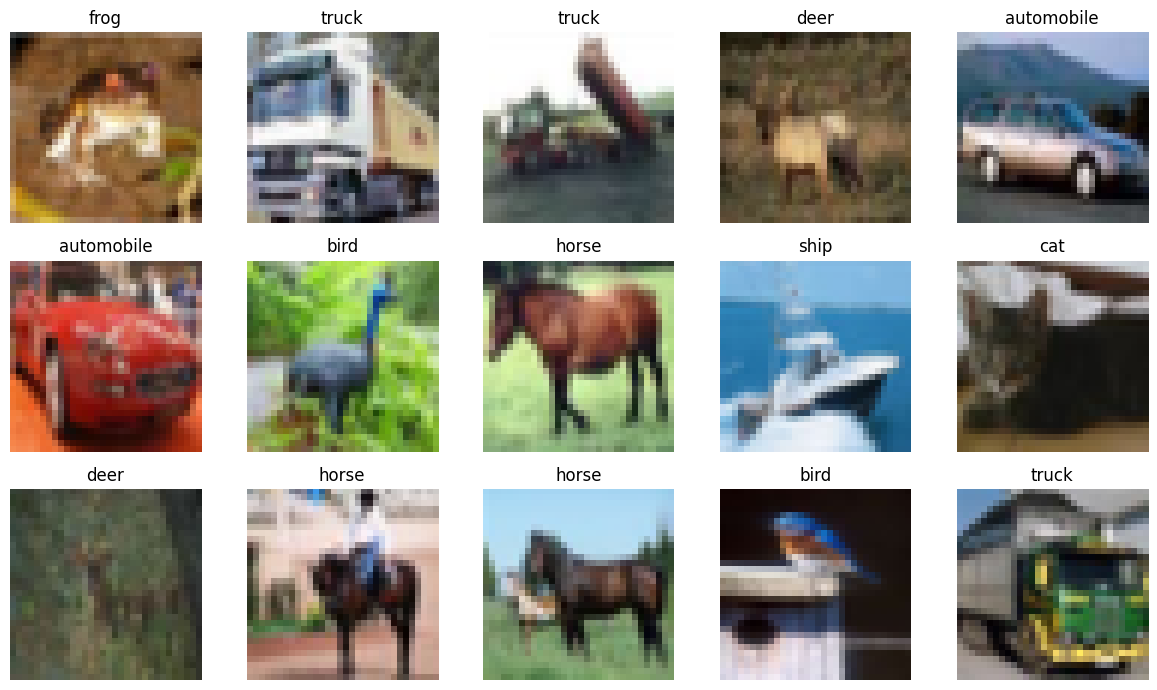

In [ ]:

# Hien thi 15 anh dau tien cua CIFAR-10
plt.figure(figsize=(12, 7))

for i in range(15):
    plt.subplot(3, 5, i + 1)

    # Hien thi anh
    plt.imshow(x_train[i])

    # Hien thi ten doi tuong
    plt.title(class_names[int(y_train[i, 0])])

    # An truc toa do
    plt.axis('off')

plt.tight_layout()
plt.show()


In [ ]:

# Buoc 5: Chuan hoa du lieu CIFAR-10

# Chuyen gia tri pixel tu 0-255 ve 0-1
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Kiem tra ket qua
print("Gia tri pixel nho nhat:", x_train.min())
print("Gia tri pixel lon nhat:", x_train.max())

print("Kich thuoc tap train:", x_train.shape)
print("Kich thuoc tap test:", x_test.shape)


Gia tri pixel nho nhat: 0.0
Gia tri pixel lon nhat: 1.0
Kich thuoc tap train: (50000, 32, 32, 3)
Kich thuoc tap test: (10000, 32, 32, 3)


In [ ]:

# Buoc 6: Xay dung mo hinh CNN

model = models.Sequential([
    # Lop dau vao
    layers.Input(shape=(32, 32, 3)),

    # Lop tich chap thu nhat
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Lop tich chap thu hai
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Lop tich chap thu ba
    layers.Conv2D(64, (3, 3), activation='relu'),

    # Chuyen thanh vector
    layers.Flatten(),

    # Lop ket noi day du
    layers.Dense(64, activation='relu'),

    # Lop dau ra 10 doi tuong
    layers.Dense(10, activation='softmax')
])

# Hien thi cau truc mo hinh
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

# Buoc 7: Bien dich mo hinh CNN

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Bien dich mo hinh CNN thanh cong!")


Bien dich mo hinh CNN thanh cong!


In [ ]:

# Buoc 8: Huan luyen mang CNN

history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2
)


Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 16s 13ms/step - accuracy: 0.3980 - loss: 1.6306 - val_accuracy: 0.5026 - val_loss: 1.3737
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.5527 - loss: 1.2528 - val_accuracy: 0.5605 - val_loss: 1.2443
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6103 - loss: 1.1046 - val_accuracy: 0.5987 - val_loss: 1.1273
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.6404 - loss: 1.0135 - val_accuracy: 0.6386 - val_loss: 1.0348
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6737 - loss: 0.9257 - val_accuracy: 0.6432 - val_loss: 1.0198
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6978 - loss: 0.8636 - val_accuracy: 0.6801 - val_loss: 0.9261
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7171 - loss: 0.8076 - val_accuracy: 0.6879 - val_loss: 0.8948
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7348 - loss: 0.7590 - val_accuracy: 

In [ ]:

# Buoc 9.1: Danh gia mo hinh tren tap test

test_loss, test_acc = model.evaluate(
    x_test,
    y_test,
    verbose=2
)

print("================================")
print(f"Test Accuracy: {test_acc * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")
print("================================")


313/313 - 3s - 10ms/step - accuracy: 0.7023 - loss: 0.8739
Test Accuracy: 70.23%
Test Loss: 0.8739


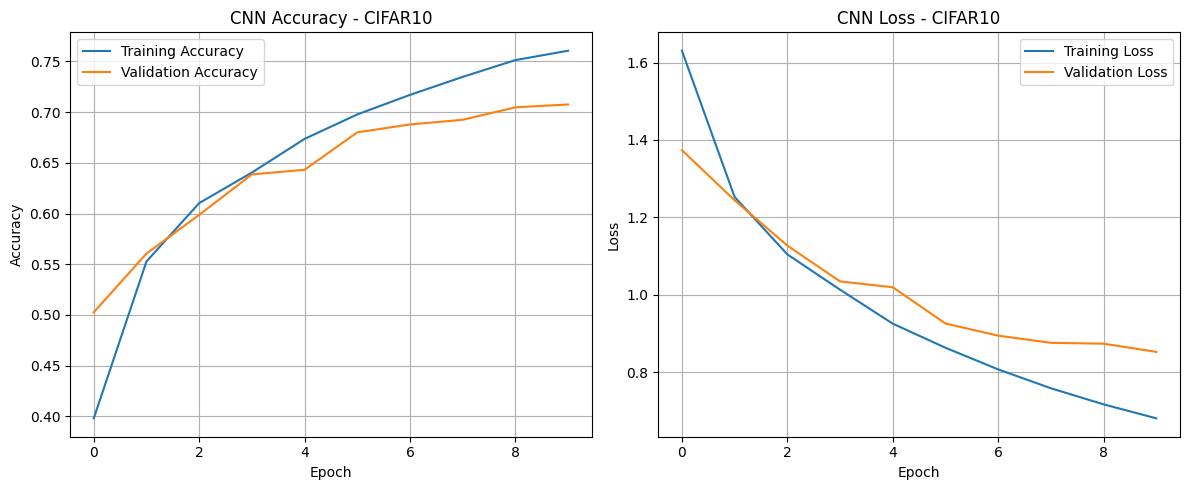

In [ ]:

# Buoc 9.2: Ve bieu do Accuracy va Loss

plt.figure(figsize=(12, 5))

# Bieu do do chinh xac
plt.subplot(1, 2, 1)

plt.plot(history.history['accuracy'],
         label='Training Accuracy')
plt.plot(history.history['val_accuracy'],
         label='Validation Accuracy')

plt.title('CNN Accuracy - CIFAR10')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Bieu do sai so
plt.subplot(1, 2, 2)

plt.plot(history.history['loss'],
         label='Training Loss')
plt.plot(history.history['val_loss'],
         label='Validation Loss')

plt.title('CNN Loss - CIFAR10')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()

# Luu bieu do
plt.savefig('cnn_training.png', dpi=150)

plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


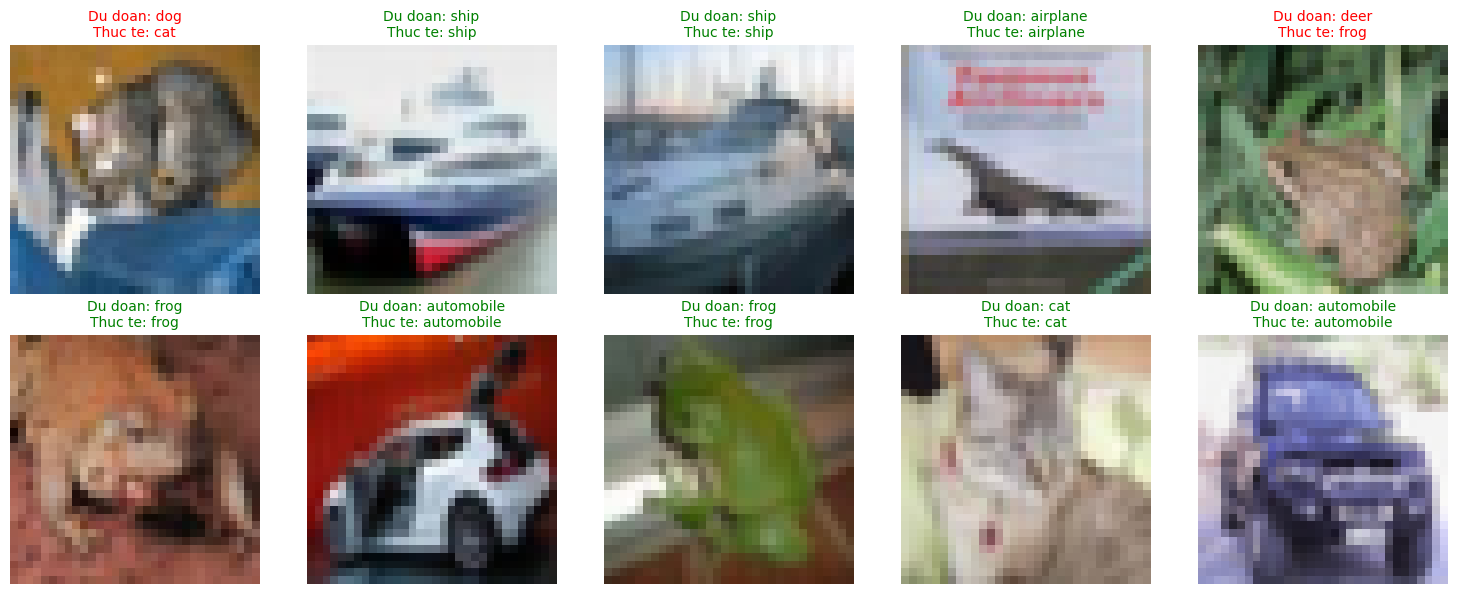

In [ ]:

# Buoc 9.3: Du doan 10 anh CIFAR-10

# Du doan 10 anh dau tien trong tap test
predictions = model.predict(x_test[:10])

plt.figure(figsize=(15, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    # Hien thi anh
    plt.imshow(x_test[i])

    # Lay nhan du doan
    predicted_label = np.argmax(predictions[i])

    # Lay nhan thuc te
    true_label = int(y_test[i, 0])

    # Mau xanh neu dung, mau do neu sai
    color = 'green' if predicted_label == true_label else 'red'

    plt.title(
        f"Du doan: {class_names[predicted_label]}\n"
        f"Thuc te: {class_names[true_label]}",
        color=color,
        fontsize=10
    )

    plt.axis('off')

plt.tight_layout()
plt.savefig('cnn_predictions.png', dpi=150)
plt.show()


In [ ]:

# Buoc 10: Luu mo hinh CNN

model.save('cnn_cifar10.keras')

print("Da luu mo hinh CNN thanh cong!")


Da luu mo hinh CNN thanh cong!
